# Статистический анализ подписки GoFast

**Портфолио-проект по продуктовой аналитике**

Сервис аренды самокатов GoFast хочет понять, связано ли использование платной подписки `Ultra` с более длинными поездками и более высокой выручкой. Дополнительно нужно проверить риск износа самокатов и оценить размер аудиторий для промоакций по длительности поездки.

В проекте используются `pandas`, `NumPy`, `SciPy`, `Matplotlib` и `Seaborn`. Основные методы: проверка качества данных, расчёт выручки, доверительные интервалы, односторонние t-тесты Уэлча, поправка Холма и сравнение теоретического нормального распределения с эмпирическим.

## 1. Бизнес-задачи и аналитический дизайн

Нужно ответить на четыре вопроса:

1. Средняя длительность поездки у подписчиков выше, чем у пользователей тарифа `Free`?
2. Средняя дистанция поездок подписчиков превышает безопасный ориентир 3130 м?
3. Средняя месячная выручка на пользователя у `Ultra` выше, чем у `Free`?
4. Какова доля поездок подписчиков длительностью более 30 минут и от 20 до 30 минут?

Для статистических тестов единицей анализа будет **пользователь**, а не отдельная поездка. У одного человека несколько поездок, поэтому тест на строках поездок создавал бы псевдорепликацию и искусственно занижал p-value. Для каждого пользователя сначала рассчитывается его средняя метрика, после чего сравниваются независимые пользовательские выборки.

> Исследование наблюдательное: статистическая связь тарифа с метриками не доказывает причинный эффект подписки. Пользователи могли самостоятельно выбрать тариф из-за уже существующих привычек.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"free": "#F97316", "ultra": "#2563EB"}
RANDOM_STATE = 42
ALPHA = 0.05

## 2. Данные

Используются три таблицы за 2021 год:

| Таблица | Содержание | Ключевые поля |
|---|---|---|
| `users_go.csv` | Профиль пользователя | `user_id`, возраст, город, тариф |
| `rides_go.csv` | Отдельные поездки | `user_id`, дистанция, длительность, дата |
| `subscriptions_go.csv` | Условия тарифов | цена минуты, старта и подписки |

Ноутбук сначала ищет файлы в папке `data/`, а при их отсутствии загружает открытые учебные данные по ссылкам Яндекс Практикума.

In [2]:
DATA_DIR = Path("data")
URLS = {
    "users_go.csv": "https://code.s3.yandex.net/datasets/users_go.csv",
    "rides_go.csv": "https://code.s3.yandex.net/datasets/rides_go.csv",
    "subscriptions_go.csv": "https://code.s3.yandex.net/datasets/subscriptions_go.csv",
}


def read_dataset(filename: str, **kwargs) -> pd.DataFrame:
    local_path = DATA_DIR / filename
    source = local_path if local_path.exists() else URLS[filename]
    return pd.read_csv(source, **kwargs)


users_raw = read_dataset("users_go.csv")
rides_raw = read_dataset("rides_go.csv", parse_dates=["date"])
subscriptions = read_dataset("subscriptions_go.csv")

dataset_overview = pd.DataFrame(
    {
        "таблица": ["users", "rides", "subscriptions"],
        "строки": [len(users_raw), len(rides_raw), len(subscriptions)],
        "столбцы": [users_raw.shape[1], rides_raw.shape[1], subscriptions.shape[1]],
        "полные дубликаты": [
            users_raw.duplicated().sum(),
            rides_raw.duplicated().sum(),
            subscriptions.duplicated().sum(),
        ],
        "пропуски": [
            users_raw.isna().sum().sum(),
            rides_raw.isna().sum().sum(),
            subscriptions.isna().sum().sum(),
        ],
    }
)

display(dataset_overview)
print(f"Период поездок: {rides_raw['date'].min():%d.%m.%Y} — {rides_raw['date'].max():%d.%m.%Y}")

Период поездок: 01.01.2021 — 30.12.2021


,таблица,строки,столбцы,полные дубликаты,пропуски
0,users,1565,5,31,0
1,rides,18068,4,0,0
2,subscriptions,2,4,0,0


## 3. Предобработка и контроль качества

В таблице пользователей есть полные дубликаты. После их удаления связь `user_id → профиль пользователя` должна стать однозначной. Объединения выполняются с параметром `validate`, чтобы случайное отношение «многие ко многим» не размножило строки.

Для поиска технических ошибок рассчитана средняя скорость поездки. Значения выше 30 км/ч считаются невозможными для прокатного самоката с учётом небольшого запаса на погрешность GPS.

In [3]:
users = users_raw.drop_duplicates().copy()

assert users["user_id"].is_unique, "После удаления дублей user_id должен быть уникальным"
assert rides_raw["user_id"].isin(users["user_id"]).all(), "Есть поездки без профиля пользователя"

rides_enriched = (
    rides_raw
    .merge(users, on="user_id", how="left", validate="many_to_one")
    .merge(subscriptions, on="subscription_type", how="left", validate="many_to_one")
)

rides_enriched["speed_kmh"] = (
    rides_enriched["distance"] / 1000 / (rides_enriched["duration"] / 60)
)
rides_enriched["is_invalid_speed"] = rides_enriched["speed_kmh"] > 30

anomaly_summary = (
    rides_enriched.loc[rides_enriched["is_invalid_speed"]]
    .groupby("subscription_type", as_index=False)
    .agg(
        аномальных_поездок=("user_id", "size"),
        пользователей=("user_id", "nunique"),
        средняя_дистанция_м=("distance", "mean"),
        средняя_длительность_мин=("duration", "mean"),
        средняя_скорость_кмч=("speed_kmh", "mean"),
    )
)

display(anomaly_summary.round(2))
print(
    f"Доля аномальных поездок: "
    f"{rides_enriched['is_invalid_speed'].mean():.2%} "
    f"({rides_enriched['is_invalid_speed'].sum()} из {len(rides_enriched)})"
)

Доля аномальных поездок: 0.53% (95 из 18068)


,subscription_type,аномальных_поездок,пользователей,средняя_дистанция_м,средняя_длительность_мин,средняя_скорость_кмч
0,free,95,90,"5,113.18",0.50,613.58


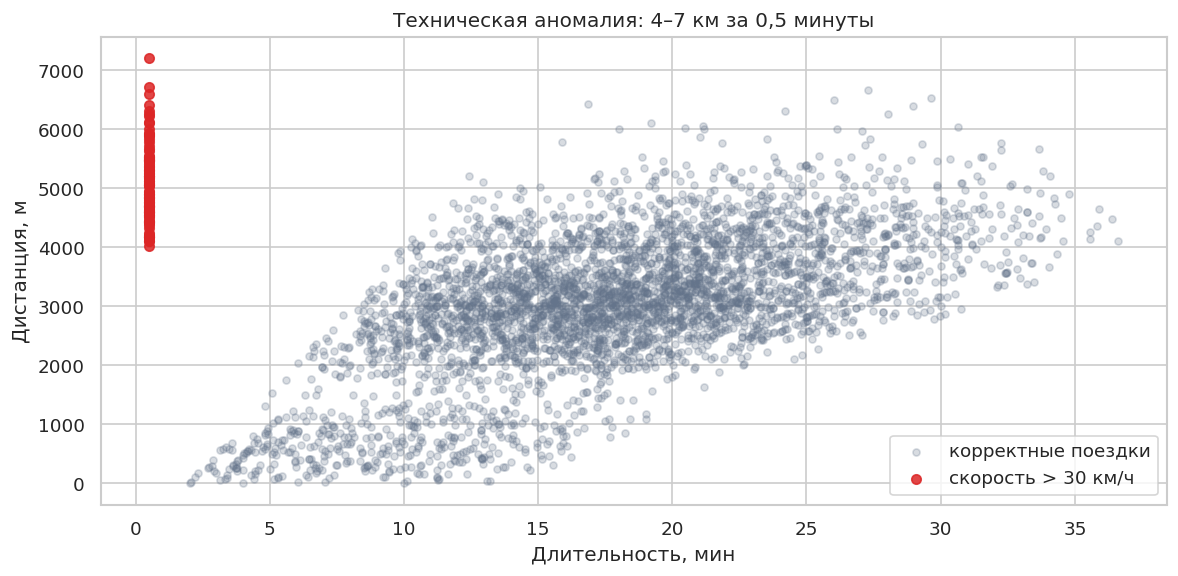

In [4]:
valid_sample = rides_enriched.loc[~rides_enriched["is_invalid_speed"]].sample(
    n=4_000, random_state=RANDOM_STATE
)
invalid_sample = rides_enriched.loc[rides_enriched["is_invalid_speed"]]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(
    valid_sample["duration"], valid_sample["distance"],
    s=18, alpha=0.25, color="#64748B", label="корректные поездки"
)
ax.scatter(
    invalid_sample["duration"], invalid_sample["distance"],
    s=32, alpha=0.85, color="#DC2626", label="скорость > 30 км/ч"
)
ax.set(
    title="Техническая аномалия: 4–7 км за 0,5 минуты",
    xlabel="Длительность, мин",
    ylabel="Дистанция, м",
)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

Все 95 аномальных строк имеют длительность ровно 0,5 минуты и дистанцию более 4 км; средняя расчётная скорость превышает 600 км/ч. Это не редкие, но допустимые поездки, а ошибка телеметрии. Строки исключаются из расчёта длительности, дистанции и модельной выручки. Доля удаления — всего около 0,53%.

Для тарификации сохраняется исходная фактическая длительность, а оплачиваемые минуты рассчитываются отдельно через `ceil`: каждая начатая минута оплачивается полностью. Обычное `round()` систематически занижало бы выручку.

In [5]:
rides = rides_enriched.loc[~rides_enriched["is_invalid_speed"]].copy()
rides["month"] = rides["date"].dt.to_period("M").astype(str)
rides["billed_duration"] = np.ceil(rides["duration"]).astype("int16")

assert len(rides) == len(rides_enriched) - 95
assert rides.isna().sum().sum() == 0
assert rides["speed_kmh"].max() <= 30
assert (rides["billed_duration"] >= rides["duration"]).all()

print(f"Итоговая аналитическая выборка: {len(rides):,} поездок, {rides['user_id'].nunique():,} пользователей")

Итоговая аналитическая выборка: 17,973 поездок, 1,534 пользователей


## 4. Исследовательский анализ

Сначала рассмотрим состав аудитории. Для пользовательских характеристик используется дедуплицированная таблица `users`, поэтому один человек учитывается один раз.

,показатель,значение
0,Пользователи,"1,534"
1,Средний возраст,24.9 года
2,Медианный возраст,25 лет
3,Доля младше 18 лет,5.1%
4,Доля Ultra,45.6%


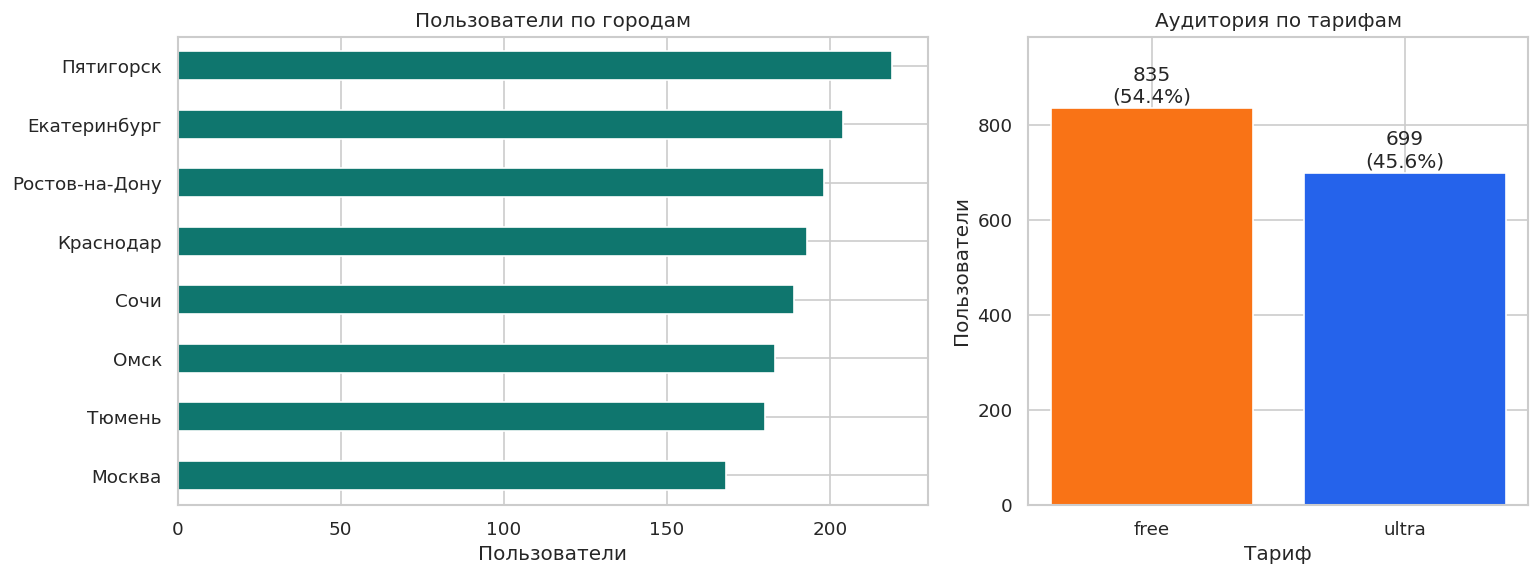

In [6]:
user_profile = pd.DataFrame(
    {
        "показатель": [
            "Пользователи",
            "Средний возраст",
            "Медианный возраст",
            "Доля младше 18 лет",
            "Доля Ultra",
        ],
        "значение": [
            f"{len(users):,}",
            f"{users['age'].mean():.1f} года",
            f"{users['age'].median():.0f} лет",
            f"{(users['age'] < 18).mean():.1%}",
            f"{(users['subscription_type'] == 'ultra').mean():.1%}",
        ],
    }
)
display(user_profile)

city_counts = users["city"].value_counts().sort_values()
subscription_counts = users["subscription_type"].value_counts().reindex(["free", "ultra"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.5, 1]})

city_counts.plot(kind="barh", ax=axes[0], color="#0F766E")
axes[0].set(title="Пользователи по городам", xlabel="Пользователи", ylabel="")

axes[1].bar(
    subscription_counts.index,
    subscription_counts.values,
    color=[COLORS["free"], COLORS["ultra"]],
)
axes[1].set(title="Аудитория по тарифам", xlabel="Тариф", ylabel="Пользователи")
axes[1].set_ylim(0, subscription_counts.max() * 1.18)
for index, value in enumerate(subscription_counts.values):
    axes[1].text(index, value + 12, f"{value}\n({value / subscription_counts.sum():.1%})", ha="center")

plt.tight_layout()
plt.show()

,пользователи,поездки,средняя_длительность_мин,медианная_длительность_мин,средняя_дистанция_м,медианная_дистанция_м
subscription_type,,,,,,
free,835,11473,17.53,17.38,"3,028.37","3,102.08"
ultra,699,6500,18.54,18.18,"3,115.45","3,148.64"


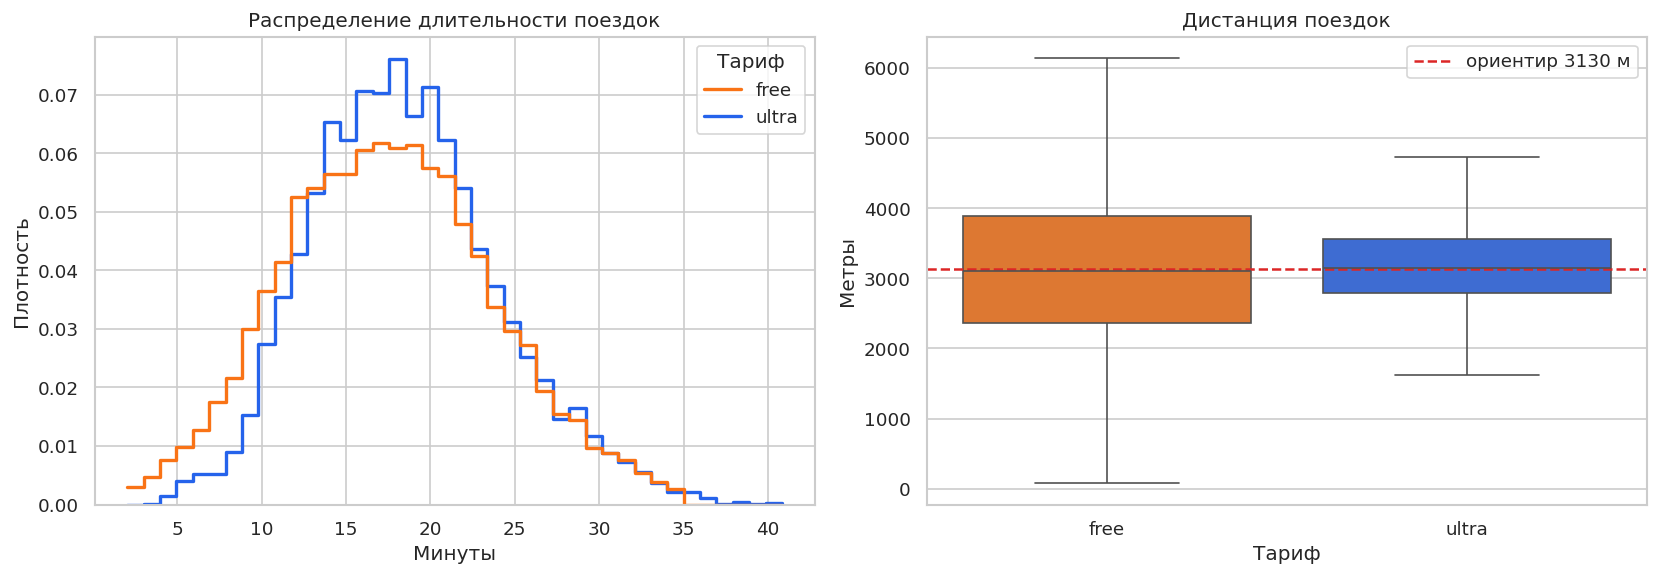

In [7]:
ride_profile = (
    rides.groupby("subscription_type")
    .agg(
        пользователи=("user_id", "nunique"),
        поездки=("user_id", "size"),
        средняя_длительность_мин=("duration", "mean"),
        медианная_длительность_мин=("duration", "median"),
        средняя_дистанция_м=("distance", "mean"),
        медианная_дистанция_м=("distance", "median"),
    )
    .reindex(["free", "ultra"])
)
display(ride_profile.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=rides, x="duration", hue="subscription_type",
    hue_order=["free", "ultra"], palette=COLORS,
    bins=40, stat="density", common_norm=False,
    element="step", fill=False, linewidth=2, ax=axes[0],
)
axes[0].set(title="Распределение длительности поездок", xlabel="Минуты", ylabel="Плотность")
axes[0].get_legend().set_title("Тариф")

sns.boxplot(
    data=rides, x="subscription_type", y="distance",
    order=["free", "ultra"], palette=COLORS,
    showfliers=False, ax=axes[1],
)
axes[1].axhline(3130, color="#DC2626", linestyle="--", linewidth=1.5, label="ориентир 3130 м")
axes[1].set(title="Дистанция поездок", xlabel="Тариф", ylabel="Метры")
axes[1].legend()

plt.tight_layout()
plt.show()

На уровне отдельных поездок подписчики в среднем едут дольше и немного дальше. Однако визуальное различие ещё не отвечает на вопрос о статистической значимости: повторные поездки одного пользователя связаны между собой, поэтому ниже метрики агрегируются до уровня пользователя.

## 5. Расчёт месячной выручки

Для каждой пары «пользователь — месяц» рассчитывается:

\[
Revenue = StartPrice \times Rides + MinutePrice \times BilledMinutes + SubscriptionFee
\]

Абонентская плата начисляется один раз на активного пользователя в каждом месяце, присутствующем в данных.

In [8]:
monthly_revenue = (
    rides.groupby(["user_id", "subscription_type", "month"], as_index=False)
    .agg(
        rides_count=("user_id", "size"),
        total_distance=("distance", "sum"),
        total_duration=("duration", "sum"),
        billed_minutes=("billed_duration", "sum"),
        minute_price=("minute_price", "first"),
        start_ride_price=("start_ride_price", "first"),
        subscription_fee=("subscription_fee", "first"),
    )
)

monthly_revenue["revenue"] = (
    monthly_revenue["start_ride_price"] * monthly_revenue["rides_count"]
    + monthly_revenue["minute_price"] * monthly_revenue["billed_minutes"]
    + monthly_revenue["subscription_fee"]
)

revenue_summary = (
    monthly_revenue.groupby("subscription_type")
    .agg(
        пользователей=("user_id", "nunique"),
        пользователь_месяцев=("user_id", "size"),
        средняя_выручка=("revenue", "mean"),
        медианная_выручка=("revenue", "median"),
        суммарная_выручка=("revenue", "sum"),
    )
    .reindex(["free", "ultra"])
)
display(revenue_summary.round(2))

,пользователей,пользователь_месяцев,средняя_выручка,медианная_выручка,суммарная_выручка
subscription_type,,,,,
free,835,6767,329.33,274.00,2228594
ultra,699,4533,362.79,337.00,1644537


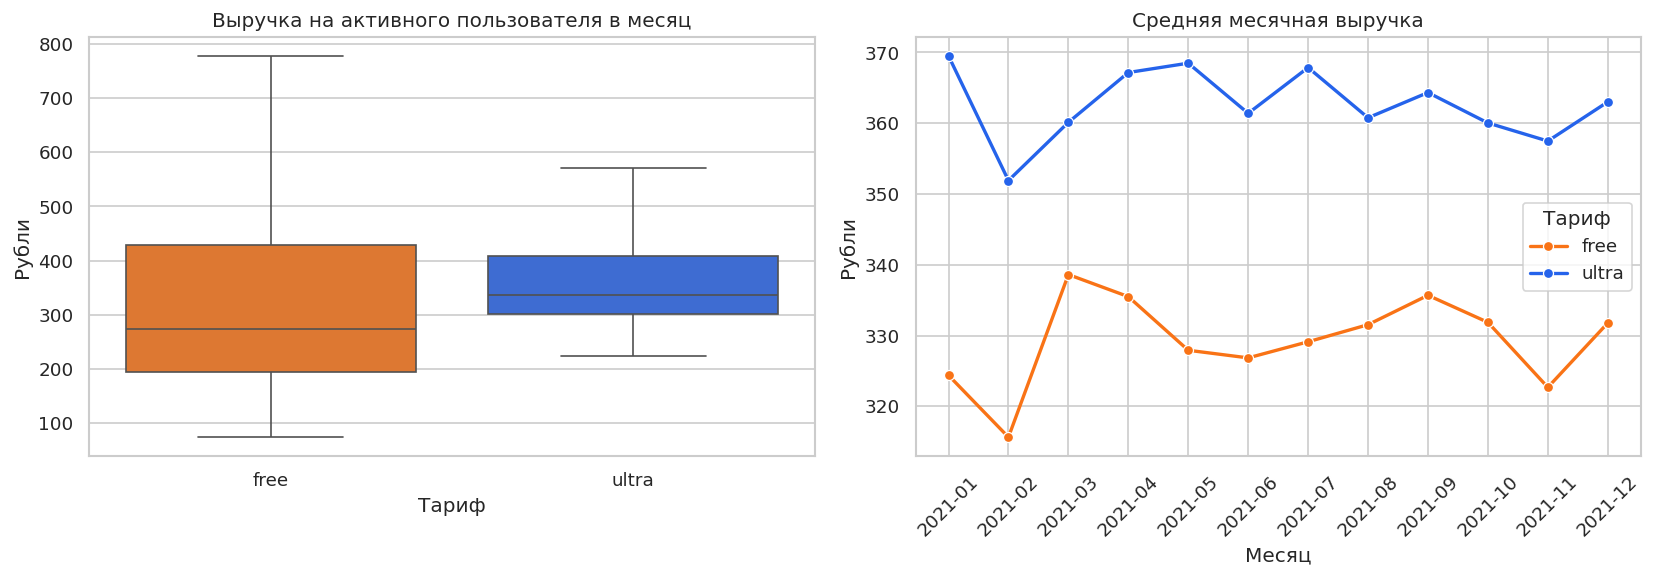

In [9]:
monthly_trend = (
    monthly_revenue.groupby(["month", "subscription_type"], as_index=False)["revenue"]
    .mean()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=monthly_revenue, x="subscription_type", y="revenue",
    order=["free", "ultra"], palette=COLORS,
    showfliers=False, ax=axes[0],
)
axes[0].set(title="Выручка на активного пользователя в месяц", xlabel="Тариф", ylabel="Рубли")

sns.lineplot(
    data=monthly_trend, x="month", y="revenue", hue="subscription_type",
    hue_order=["free", "ultra"], palette=COLORS,
    marker="o", linewidth=2, ax=axes[1],
)
axes[1].set(title="Средняя месячная выручка", xlabel="Месяц", ylabel="Рубли")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="Тариф")

plt.tight_layout()
plt.show()

У тарифа `Free` выше суммарная выручка, потому что в группе больше пользователей и пользователь-месяцев. Это не означает, что тариф выгоднее на одного клиента. Для сравнения тарифов далее используется средняя месячная выручка каждого пользователя: сначала среднее по месяцам внутри пользователя, затем сравнение пользователей между тарифами.

## 6. Проверка гипотез

Порог значимости для семейства тестов — 5%. Используются:

- односторонний t-тест Уэлча для двух независимых групп — он не требует равенства дисперсий;
- одновыборочный t-тест для сравнения средней дистанции с 3130 м;
- 95%-е двусторонние доверительные интервалы для оценки величины эффекта;
- поправка Холма для контроля семейной вероятности ошибки первого рода по трём гипотезам;
- Hedges' g (или стандартизированный одновыборочный эффект) для оценки практической величины различий.

Большие пользовательские выборки делают t-тесты достаточно устойчивыми к умеренной ненормальности средних метрик.

In [10]:
def welch_difference_ci(sample_a, sample_b, confidence=0.95):
    sample_a = pd.Series(sample_a).dropna().astype(float)
    sample_b = pd.Series(sample_b).dropna().astype(float)
    n_a, n_b = len(sample_a), len(sample_b)
    var_a, var_b = sample_a.var(ddof=1), sample_b.var(ddof=1)
    standard_error = np.sqrt(var_a / n_a + var_b / n_b)
    degrees_freedom = (var_a / n_a + var_b / n_b) ** 2 / (
        (var_a / n_a) ** 2 / (n_a - 1) + (var_b / n_b) ** 2 / (n_b - 1)
    )
    difference = sample_a.mean() - sample_b.mean()
    critical = stats.t.ppf((1 + confidence) / 2, degrees_freedom)
    return difference, (difference - critical * standard_error, difference + critical * standard_error)


def hedges_g(sample_a, sample_b):
    sample_a = pd.Series(sample_a).dropna().astype(float)
    sample_b = pd.Series(sample_b).dropna().astype(float)
    n_a, n_b = len(sample_a), len(sample_b)
    pooled_sd = np.sqrt(
        ((n_a - 1) * sample_a.var(ddof=1) + (n_b - 1) * sample_b.var(ddof=1))
        / (n_a + n_b - 2)
    )
    correction = 1 - 3 / (4 * (n_a + n_b) - 9)
    return (sample_a.mean() - sample_b.mean()) / pooled_sd * correction


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    sorted_p = p_values[order]
    multipliers = len(p_values) - np.arange(len(p_values))
    adjusted_sorted = np.maximum.accumulate(sorted_p * multipliers)
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    return adjusted

In [11]:
# H1: средняя пользовательская длительность Ultra > Free
user_duration = (
    rides.groupby(["user_id", "subscription_type"], as_index=False)["duration"]
    .mean()
)
duration_ultra = user_duration.query("subscription_type == 'ultra'")["duration"]
duration_free = user_duration.query("subscription_type == 'free'")["duration"]
duration_test = stats.ttest_ind(
    duration_ultra, duration_free, equal_var=False, alternative="greater"
)
duration_diff, duration_ci = welch_difference_ci(duration_ultra, duration_free)

# H1: средняя пользовательская дистанция Ultra > 3130 м
distance_ultra = (
    rides.query("subscription_type == 'ultra'")
    .groupby("user_id")["distance"]
    .mean()
)
distance_test = stats.ttest_1samp(distance_ultra, 3130, alternative="greater")
distance_mean = distance_ultra.mean()
distance_se = stats.sem(distance_ultra)
distance_ci = stats.t.interval(
    0.95, df=len(distance_ultra) - 1, loc=distance_mean, scale=distance_se
)

# H1: средняя месячная выручка пользователя Ultra > Free
user_revenue = (
    monthly_revenue.groupby(["user_id", "subscription_type"], as_index=False)["revenue"]
    .mean()
)
revenue_ultra = user_revenue.query("subscription_type == 'ultra'")["revenue"]
revenue_free = user_revenue.query("subscription_type == 'free'")["revenue"]
revenue_test = stats.ttest_ind(
    revenue_ultra, revenue_free, equal_var=False, alternative="greater"
)
revenue_diff, revenue_ci = welch_difference_ci(revenue_ultra, revenue_free)

raw_p_values = np.array([
    duration_test.pvalue,
    distance_test.pvalue,
    revenue_test.pvalue,
])
adjusted_p_values = holm_adjust(raw_p_values)

test_results = pd.DataFrame(
    {
        "гипотеза H1": [
            "Длительность Ultra > Free",
            "Дистанция Ultra > 3130 м",
            "Выручка Ultra > Free",
        ],
        "оценка": [
            f"{duration_ultra.mean():.2f} vs {duration_free.mean():.2f} мин; Δ={duration_diff:.2f}",
            f"{distance_mean:.2f} м; Δ={distance_mean - 3130:.2f}",
            f"{revenue_ultra.mean():.2f} vs {revenue_free.mean():.2f} руб; Δ={revenue_diff:.2f}",
        ],
        "95% ДИ": [
            f"[{duration_ci[0]:.2f}; {duration_ci[1]:.2f}] мин для Δ",
            f"[{distance_ci[0]:.2f}; {distance_ci[1]:.2f}] м для среднего",
            f"[{revenue_ci[0]:.2f}; {revenue_ci[1]:.2f}] руб для Δ",
        ],
        "p-value": [f"{value:.3g}" for value in raw_p_values],
        "p-value Холма": [f"{value:.3g}" for value in adjusted_p_values],
        "эффект": [
            f"g={hedges_g(duration_ultra, duration_free):.2f}",
            f"d={(distance_mean - 3130) / distance_ultra.std(ddof=1):.2f}",
            f"g={hedges_g(revenue_ultra, revenue_free):.2f}",
        ],
        "решение при α=0,05": [
            "H0 отклоняется" if value < ALPHA else "H0 не отклоняется"
            for value in adjusted_p_values
        ],
    }
)

display(test_results)

,гипотеза H1,оценка,95% ДИ,p-value,p-value Холма,эффект,"решение при α=0,05"
0,Длительность Ultra > Free,18.57 vs 17.53 мин; Δ=1.05,[0.86; 1.24] мин для Δ,1.04e-26,2.09e-26,g=0.56,H0 отклоняется
1,Дистанция Ultra > 3130 м,3113.46 м; Δ=-16.54,[3091.20; 3135.72] м для среднего,0.928,0.928,d=-0.06,H0 не отклоняется
2,Выручка Ultra > Free,363.07 vs 329.13 руб; Δ=33.94,[28.77; 39.11] руб для Δ,3.35e-36,1e-35,g=0.63,H0 отклоняется


In [12]:
display(Markdown(f"""
### Интерпретация статистических тестов

- **Длительность.** Средняя длительность на пользователя у `Ultra` составляет **{duration_ultra.mean():.2f} мин** против **{duration_free.mean():.2f} мин** у `Free`. Разница **{duration_diff:.2f} мин**; 95% ДИ **[{duration_ci[0]:.2f}; {duration_ci[1]:.2f}]**. После поправки Холма результат статистически значим, а Hedges' g = **{hedges_g(duration_ultra, duration_free):.2f}** соответствует эффекту средней величины.

- **Дистанция и износ.** Средняя пользовательская дистанция у `Ultra` — **{distance_mean:.0f} м**, 95% ДИ **[{distance_ci[0]:.0f}; {distance_ci[1]:.0f}] м**. Интервал пересекает ориентир 3130 м, а односторонний p-value = **{distance_test.pvalue:.3f}**. Данных недостаточно, чтобы утверждать, что средняя дистанция превышает безопасный ориентир. Это **не доказывает**, что она гарантированно ниже 3130 м.

- **Выручка.** Средняя месячная выручка на пользователя у `Ultra` составляет **{revenue_ultra.mean():.2f} руб.** против **{revenue_free.mean():.2f} руб.** у `Free`. Разница **{revenue_diff:.2f} руб.**; 95% ДИ **[{revenue_ci[0]:.2f}; {revenue_ci[1]:.2f}]**. Различие устойчиво после поправки Холма; Hedges' g = **{hedges_g(revenue_ultra, revenue_free):.2f}**.
"""))

<IPython.core.display.Markdown object>

## 7. Аудитории промоакций и нормальная аппроксимация

Бизнес рассматривает скидку для подписчиков с поездками более 30 минут, а также вариант промо для поездок от 20 до 30 минут. Учебная постановка предполагает нормальное распределение длительности. Проверим не только модельную вероятность по `CDF`, но и фактическую долю в наблюдаемых данных.

Также сравним 90-й процентиль дистанции по нормальной модели (`PPF`) с эмпирическим процентилем. Это показывает, насколько чувствительно бизнес-решение к предположению о форме распределения.

In [13]:
ultra_duration_rides = rides.query("subscription_type == 'ultra'")["duration"]
duration_mu = ultra_duration_rides.mean()
duration_sigma = ultra_duration_rides.std(ddof=1)

normal_share_over_30 = stats.norm.sf(30, loc=duration_mu, scale=duration_sigma)
empirical_share_over_30 = (ultra_duration_rides > 30).mean()

normal_share_20_30 = (
    stats.norm.cdf(30, loc=duration_mu, scale=duration_sigma)
    - stats.norm.cdf(20, loc=duration_mu, scale=duration_sigma)
)
empirical_share_20_30 = ultra_duration_rides.between(20, 30, inclusive="both").mean()

distance_mu = rides["distance"].mean()
distance_sigma = rides["distance"].std(ddof=1)
normal_distance_p90 = stats.norm.ppf(0.90, loc=distance_mu, scale=distance_sigma)
empirical_distance_p90 = rides["distance"].quantile(0.90)

distribution_comparison = pd.DataFrame(
    {
        "метрика": [
            "Доля поездок Ultra > 30 мин",
            "Доля поездок Ultra от 20 до 30 мин",
            "90-й процентиль дистанции всех поездок",
        ],
        "нормальная модель": [
            f"{normal_share_over_30:.1%}",
            f"{normal_share_20_30:.1%}",
            f"{normal_distance_p90:.0f} м",
        ],
        "эмпирическая оценка": [
            f"{empirical_share_over_30:.1%}",
            f"{empirical_share_20_30:.1%}",
            f"{empirical_distance_p90:.0f} м",
        ],
    }
)
display(distribution_comparison)

,метрика,нормальная модель,эмпирическая оценка
0,Доля поездок Ultra > 30 мин,2.0%,3.3%
1,Доля поездок Ultra от 20 до 30 мин,37.7%,34.0%
2,90-й процентиль дистанции всех поездок,4481 м,4373 м


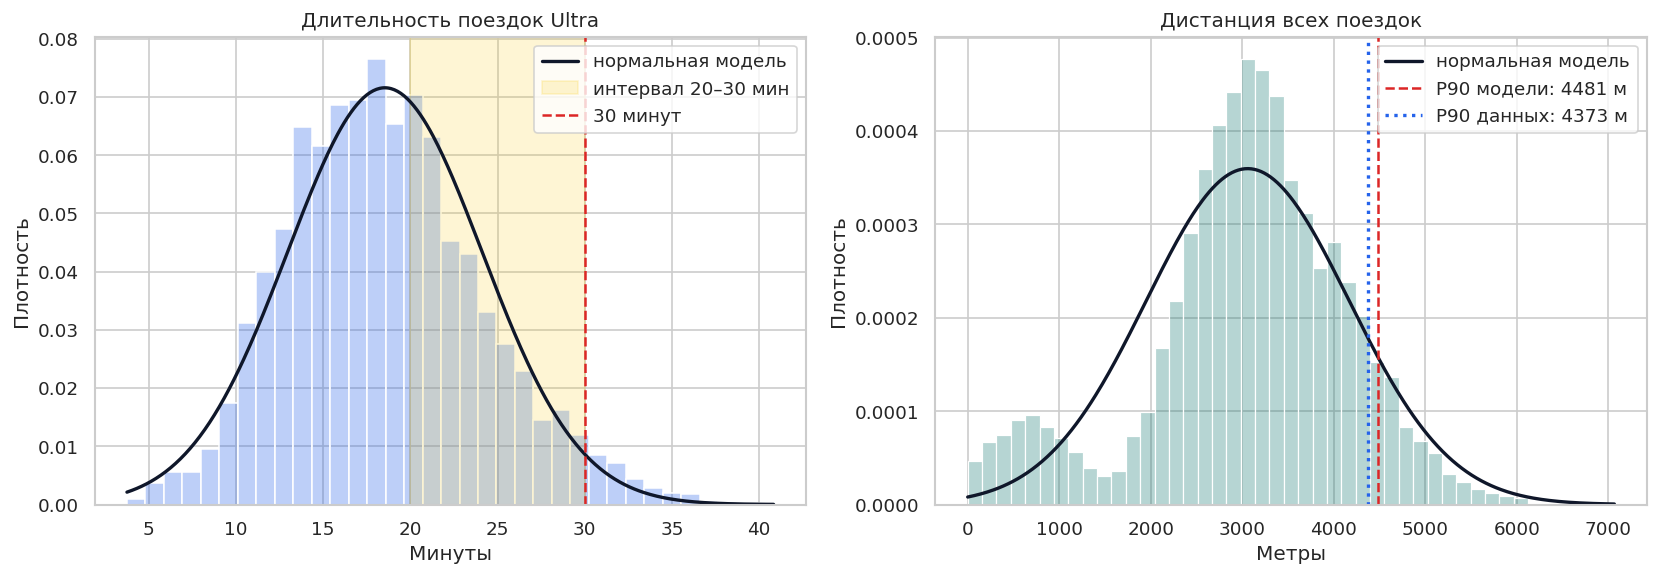

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Длительность Ultra и нормальная аппроксимация
sns.histplot(
    ultra_duration_rides, bins=35, stat="density",
    color=COLORS["ultra"], alpha=0.30, ax=axes[0],
)
x_duration = np.linspace(ultra_duration_rides.min(), ultra_duration_rides.max(), 400)
axes[0].plot(
    x_duration,
    stats.norm.pdf(x_duration, duration_mu, duration_sigma),
    color="#0F172A", linewidth=2, label="нормальная модель",
)
axes[0].axvspan(20, 30, color="#FACC15", alpha=0.18, label="интервал 20–30 мин")
axes[0].axvline(30, color="#DC2626", linestyle="--", label="30 минут")
axes[0].set(title="Длительность поездок Ultra", xlabel="Минуты", ylabel="Плотность")
axes[0].legend()

# Дистанция и 90-е процентили
sns.histplot(
    rides["distance"], bins=45, stat="density",
    color="#0F766E", alpha=0.30, ax=axes[1],
)
x_distance = np.linspace(rides["distance"].min(), rides["distance"].max(), 400)
axes[1].plot(
    x_distance,
    stats.norm.pdf(x_distance, distance_mu, distance_sigma),
    color="#0F172A", linewidth=2, label="нормальная модель",
)
axes[1].axvline(
    normal_distance_p90, color="#DC2626", linestyle="--",
    label=f"P90 модели: {normal_distance_p90:.0f} м",
)
axes[1].axvline(
    empirical_distance_p90, color="#2563EB", linestyle=":", linewidth=2,
    label=f"P90 данных: {empirical_distance_p90:.0f} м",
)
axes[1].set(title="Дистанция всех поездок", xlabel="Метры", ylabel="Плотность")
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
display(Markdown(f"""
## 8. Итоговые выводы и рекомендации

1. **Подписчики ездят дольше.** На уровне независимых пользователей разница составляет **{duration_diff:.2f} минуты** (95% ДИ: {duration_ci[0]:.2f}–{duration_ci[1]:.2f}); результат сохраняется после поправки на множественные проверки.

2. **Средняя месячная выручка на пользователя выше у Ultra на {revenue_diff:.2f} руб.** (95% ДИ: {revenue_ci[0]:.2f}–{revenue_ci[1]:.2f}). Продвижение подписки выглядит экономически перспективным, но причинный инкремент следует подтвердить экспериментом.

3. **Превышение среднего ориентира 3130 м не подтверждено.** Оценка для Ultra равна {distance_mean:.0f} м, однако доверительный интервал пересекает порог. Для управления износом лучше отслеживать не только среднее, но и верхние процентили дистанции.

4. **Промо только для поездок свыше 30 минут охватит небольшую аудиторию:** эмпирически около **{empirical_share_over_30:.1%}** поездок Ultra. Интервал 20–30 минут охватывает около **{empirical_share_20_30:.1%}** поездок и подходит для более массовой акции.

5. **Нормальная модель заметно искажает хвосты.** Для поездок Ultra свыше 30 минут она даёт {normal_share_over_30:.1%} против фактических {empirical_share_over_30:.1%}; модельный P90 дистанции отличается от эмпирического примерно на {abs(normal_distance_p90 - empirical_distance_p90):.0f} м. Для операционных порогов при наличии достаточного объёма данных предпочтительнее эмпирические квантили.

6. **Рекомендованный следующий шаг:** A/B-тест предложения подписки среди пользователей `Free` с основными метриками «выручка на назначенного пользователя», конверсия в подписку и маржинальная прибыль. Обязательно контролировать каннибализацию, удержание и расходы на обслуживание самокатов.

### Ограничения

- Данные охватывают один год и восемь городов; перенос выводов на другие периоды требует проверки.
- Выручка рассчитана по тарифной формуле, а не по фактическим транзакциям и возвратам.
- Наблюдательное сравнение не отделяет эффект подписки от самоотбора пользователей.
- 95 строк с невозможной скоростью исключены как технические ошибки; полезно выяснить их источник в системе телеметрии.
"""))

<IPython.core.display.Markdown object>